In [1]:
   pip install -q tensorflow==2.19.0 tqdm scikit-learn matplotlib seaborn albumentations opencv-python tensorboard


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 644.9/644.9 MB 2.7 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.5/5.5 MB 100.1 MB/s eta 0:00:0000:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 97.7 MB/s eta 0:00:00:00:01
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
dopamine-rl 4.1.2 requires gymnasium>=1.0.0, but you have gymnasium 0.29.0 which is incompatible.
tf-keras 2.18.0 requires tensorflow<2.19,>=2.18, but you have tensorflow 2.19.0 which is incompatible.
tensorflow-decision-forests 1.11.0 requires tensorflow==2.18.0, but you have tensorflow 2.19.0 which is incompatible.
tensorflow-text 2.18.1 requires tensorflow<2.19,>=2.18.0, but you have tensorflow 2.19.0 which is incompatible.
Note: you may need to restart the kernel to use updated packages.


In [2]:
# ========================== #
# 0. SETUP & IMPORT
# ========================== #
print("📦 Importing libraries...")
import os, shutil, random, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc
from sklearn.preprocessing import label_binarize
from tensorflow.keras.models import Model, load_model
from tensorflow.keras.layers import (Input, Conv2D, MaxPooling2D, Dense, Dropout,
                                     Flatten, BatchNormalization, GlobalAveragePooling2D,
                                     Multiply, Reshape)
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, Callback
from tensorflow.keras.optimizers import Adam
from tqdm.notebook import tqdm
import IPython
import cv2

# ========================== #
# TPU STRATEGY SETUP (SAFE)
# ========================== #
print("🧠 Checking for TPU/strategy...")
try:
    resolver = tf.distribute.cluster_resolver.TPUClusterResolver()
    tf.config.experimental_connect_to_cluster(resolver)
    tf.tpu.experimental.initialize_tpu_system(resolver)
    strategy = tf.distribute.TPUStrategy(resolver)
    print("✅ TPU initialized")
except:
    strategy = tf.distribute.get_strategy()
    print("⚠️ TPU not available. Using default strategy:", type(strategy))

# ========================== #
# 1. SPLIT DATA
# ========================== #
# print("📁 Splitting dataset...")
# root = '/kaggle/working/'
# work_dir = '/kaggle/working'
# split_dir = os.path.join(work_dir, 'split_dataset')
# train_dir, test_dir = os.path.join(split_dir, 'train'), os.path.join(split_dir, 'test')

# def split_dataset(source, train_path, test_path, split=0.8):
#     if os.path.exists(train_path): shutil.rmtree(train_path)
#     if os.path.exists(test_path): shutil.rmtree(test_path)
#     os.makedirs(train_path), os.makedirs(test_path)
#     for cls in os.listdir(source):
#         cls_path = os.path.join(source, cls)
#         if not os.path.isdir(cls_path): continue
#         imgs = os.listdir(cls_path)
#         random.shuffle(imgs)
#         os.makedirs(os.path.join(train_path, cls)), os.makedirs(os.path.join(test_path, cls))
#         split_idx = int(len(imgs)*split)
#         for i, img in enumerate(imgs):
#             dst = train_path if i < split_idx else test_path
#             shutil.copy(os.path.join(cls_path, img), os.path.join(dst, cls, img))

# split_dataset(root, train_dir, test_dir)
# print("✅ Dataset split complete.")

# ========================== #
# 1. STRATEGY SETUP
# ========================== #
# ========================== #
# 2. DATA PIPELINE (with skip)
# ========================== #
print("🔄 Loading dataset from pre-split folders...")
img_size = 224
batch_size = 64

train_dir = r'/kaggle/input/skindisease/dataset_split/train'
test_dir  = r'/kaggle/input/skindisease/dataset_split/test'

#  Classes we want to skip
skip_classes = [
    "Actinic Keratosis Basal Cell Carcinoma And Other Malignant Lesions",
    "Benign",
    "Malignant",
    "Melanoma Skin Cancer Nevi And Moles",
    "Seborrheic Keratoses And Other Benign Tumors",
    "Tinea Ringworm Candidiasis And Other Fungal Infections",
    "Fu Ringworm",
    "Fu Athlete Foot",
    "Fu Nail Fungus",
    "Cellulitis Impetigo And Other Bacterial Infections",
    "Warts Molluscum And Other Viral Infections"
]


# ✅ Get full class list from train_dir, then filter
all_classes = sorted(os.listdir(train_dir))
selected_classes = [c for c in all_classes if c not in skip_classes]

print(f" Total classes before skip: {len(all_classes)}")
print(f" Classes used after skip: {len(selected_classes)}")

train_aug = ImageDataGenerator(rescale=1./255, rotation_range=30, zoom_range=0.3,
                               width_shift_range=0.2, height_shift_range=0.2,
                               shear_range=0.2, horizontal_flip=True, fill_mode='nearest')
test_aug = ImageDataGenerator(rescale=1./255)

train_data = train_aug.flow_from_directory(
    train_dir,
    target_size=(img_size, img_size),
    batch_size=batch_size,
    class_mode='categorical',
    classes=selected_classes   # 👈 only include allowed classes
)

test_data = test_aug.flow_from_directory(
    test_dir,
    target_size=(img_size, img_size),
    batch_size=batch_size,
    class_mode='categorical',
    shuffle=False,
    classes=selected_classes   # 👈 same here
)

num_classes = train_data.num_classes
print(f"✅ Final class count used: {num_classes}")


📦 Importing libraries...


2025-08-23 13:28:17.627945: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1755955697.650715      36 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1755955697.657515      36 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1755955697.676121      36 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1755955697.676152      36 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1755955697.676155      36 computation_placer.cc:177] computation placer alr

🧠 Checking for TPU/strategy...
⚠️ TPU not available. Using default strategy: <class 'tensorflow.python.distribute.distribute_lib._DefaultDistributionStrategy'>
🔄 Loading dataset from pre-split folders...
 Total classes before skip: 35
 Classes used after skip: 24
Found 54840 images belonging to 24 classes.
Found 13728 images belonging to 24 classes.
✅ Final class count used: 24


In [3]:
# ========================== #
# 3. MODEL W/ SE BLOCKS
# ========================== #
print("🧱 Building the model with SE blocks...")

def se_block(x, ratio=16):
    filters = x.shape[-1]
    se = GlobalAveragePooling2D()(x)
    se = Dense(filters // ratio, activation='relu')(se)
    se = Dense(filters, activation='sigmoid')(se)
    se = Reshape((1, 1, filters))(se)
    return Multiply()([x, se])

def build_model(input_shape=(img_size, img_size, 3), classes=num_classes):
    inputs = Input(shape=input_shape)

    def conv_block(x, filters):
        x = Conv2D(filters, (3,3), padding='same', activation='relu')(x)
        x = BatchNormalization()(x)
        x = se_block(x)
        x = Conv2D(filters, (3,3), padding='same', activation='relu')(x)
        x = BatchNormalization()(x)
        x = MaxPooling2D((2,2))(x)
        return x

    x = conv_block(inputs, 64)
    x = conv_block(x, 128)
    x = conv_block(x, 256)
    x = conv_block(x, 512)

    x = GlobalAveragePooling2D(name="explain_map")(x)
    x = Dense(512, activation='relu')(x)
    x = Dropout(0.5)(x)
    outputs = Dense(classes, activation='softmax')(x)

    return Model(inputs, outputs)
work_dir = "/kaggle/working/"
model_path = os.path.join(work_dir, 'best_model.keras')

with strategy.scope():
    if os.path.exists(model_path):
        model = load_model(model_path)
        print("✅ Resumed from saved model.")
    else:
        model = build_model()
        print("🔄 New model created.")

    model.compile(optimizer=Adam(1e-4), loss='categorical_crossentropy', metrics=['accuracy'])


🧱 Building the model with SE blocks...


I0000 00:00:1755955719.983440      36 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 15513 MB memory:  -> device: 0, name: Tesla P100-PCIE-16GB, pci bus id: 0000:00:04.0, compute capability: 6.0


🔄 New model created.


In [4]:
print(len(train_data))
print(len(test_data))


857
215


In [5]:
# Check sample batch shape
x_batch, y_batch = next(iter(train_data))
print("🖼️ Input shape:", x_batch.shape)
print("🏷️ Labels shape:", y_batch.shape)


🖼️ Input shape: (64, 224, 224, 3)
🏷️ Labels shape: (64, 24)


In [6]:
model.summary()   # 🔍 Check input/output shapes


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 224, 224,  │      1,792 │ input_layer[0][0] │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 224, 224,  │        256 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 64)        │          0 │ batch_normalizat… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 4)         │        260 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 64)        │        320 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape (Reshape)   │ (None, 1, 1, 64)  │          0 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multiply (Multiply) │ (None, 224, 224,  │          0 │ batch_normalizat… │
│                     │ 64)               │            │ reshape[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 224, 224,  │     36,928 │ multiply[0][0]    │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 224, 224,  │        256 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 112, 112,  │          0 │ batch_normalizat… │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 112, 112,  │     73,856 │ max_pooling2d[0]… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 112, 112,  │        512 │ conv2d_2[0][0]    │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 128)       │          0 │ batch_normalizat… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 8)         │      1,032 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 128)       │      1,152 │ dense_2[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape_1 (Reshape) │ (None, 1, 1, 128) │          0 │ dense_3[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multiply_1          │ (None, 112, 112,  │          0 │ batch_normalizat… │
│ (Multiply)          │ 128)              │            │ reshape_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 112, 112,  │    147,584 │ multiply_1[0][0]

 Total params: 5,012,564 (19.12 MB)

 Trainable params: 5,008,724 (19.11 MB)

 Non-trainable params: 3,840 (15.00 KB)

In [8]:
# ========================== #
# 4. CALLBACKS + RESUME LOGIC
# ========================== #
print(" Setting up training callbacks...")

from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, Callback
from tensorflow.keras.models import load_model
import glob, shutil, os

#  Ensure outputs folder exists
outputs_dir = "/kaggle/working/outputs"
os.makedirs(outputs_dir, exist_ok=True)

#  Custom Callback to Save at Every Epoch
class EpochCheckpoint(Callback):
    def __init__(self, save_path):
        super(EpochCheckpoint, self).__init__()
        self.save_path = save_path

    def on_epoch_end(self, epoch, logs=None):
        file = self.save_path.format(epoch=epoch+1)
        self.model.save(file)
        # Copy checkpoint to Outputs folder for permanent storage
        shutil.copy(file, os.path.join(outputs_dir, f"model_epoch_{epoch+1}.keras"))
        print(f"✅ Saved model at epoch {epoch+1} → {file} (and copied to Outputs folder)")

# Paths
epoch_model_path = '/kaggle/working/model_epoch_{epoch}.keras'
best_model_path = '/kaggle/working/model_best.keras'

# Standard Callbacks
checkpoint = ModelCheckpoint(best_model_path, save_best_only=True)
earlystop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
epoch_save = EpochCheckpoint(epoch_model_path)

callbacks = [checkpoint, earlystop, epoch_save]

#  Resume if checkpoint exists (check both working and outputs folders)
latest_checkpoints = sorted(
    glob.glob('/kaggle/working/model_epoch_*.keras') +
    glob.glob(f'{outputs_dir}/model_epoch_*.keras')
)

if latest_checkpoints:
    latest_model = latest_checkpoints[-1]
    model = load_model(latest_model)
    # Extract last epoch from filename
    last_epoch = int(os.path.basename(latest_model).split("_")[-1].replace(".keras",""))
    initial_epoch = last_epoch
    print(f"✅ Resumed training from: {latest_model} (epoch {last_epoch})")
else:
    print(" Starting training from scratch.")
    initial_epoch = 0

# ========================== #
# 5. TRAIN MODEL
# ========================== #
print("🚀 Starting training...")
history = model.fit(
    train_data,
    validation_data=test_data,
    epochs=30,
    callbacks=callbacks,
    verbose=1,
    initial_epoch=initial_epoch  # continue from last saved epoch
)

# -------------------------- #
# Save best model permanently
# -------------------------- #
shutil.copy(best_model_path, os.path.join(outputs_dir, "model_best.keras"))
print("✅ Training complete. All checkpoints and best model saved in Outputs folder.")


 Setting up training callbacks...
✅ Resumed training from: /kaggle/working/model_epoch_3.keras (epoch 3)
🚀 Starting training...
Epoch 4/30
857/857 ━━━━━━━━━━━━━━━━━━━━ 0s 946ms/step - accuracy: 0.4718 - loss: 1.7083✅ Saved model at epoch 4 → /kaggle/working/model_epoch_4.keras (and copied to Outputs folder)
857/857 ━━━━━━━━━━━━━━━━━━━━ 890s 1s/step - accuracy: 0.4718 - loss: 1.7083 - val_accuracy: 0.4141 - val_loss: 1.9031
Epoch 5/30
857/857 ━━━━━━━━━━━━━━━━━━━━ 0s 921ms/step - accuracy: 0.5213 - loss: 1.5481✅ Saved model at epoch 5 → /kaggle/working/model_epoch_5.keras (and copied to Outputs folder)
857/857 ━━━━━━━━━━━━━━━━━━━━ 849s 991ms/step - accuracy: 0.5213 - loss: 1.5481 - val_accuracy: 0.4893 - val_loss: 1.6705
Epoch 6/30
857/857 ━━━━━━━━━━━━━━━━━━━━ 0s 947ms/step - accuracy: 0.5658 - loss: 1.4013✅ Saved model at epoch 6 → /kaggle/working/model_epoch_6.keras (and copied to Outputs folder)
857/857 ━━━━━━━━━━━━━━━━━━━━ 876s 1s/step - accuracy: 0.5658 - loss: 1.4013 - val_accuracy

re-train 3rd

In [12]:
model.save('/kaggle/working/final_model.keras')


🔍 Evaluating model...
215/215 ━━━━━━━━━━━━━━━━━━━━ 62s 289ms/step - accuracy: 0.8637 - loss: 0.4701

✅ Test Accuracy: 88.55%
✅ Test Loss: 0.3921
📊 Generating confusion matrix...
215/215 ━━━━━━━━━━━━━━━━━━━━ 59s 264ms/step


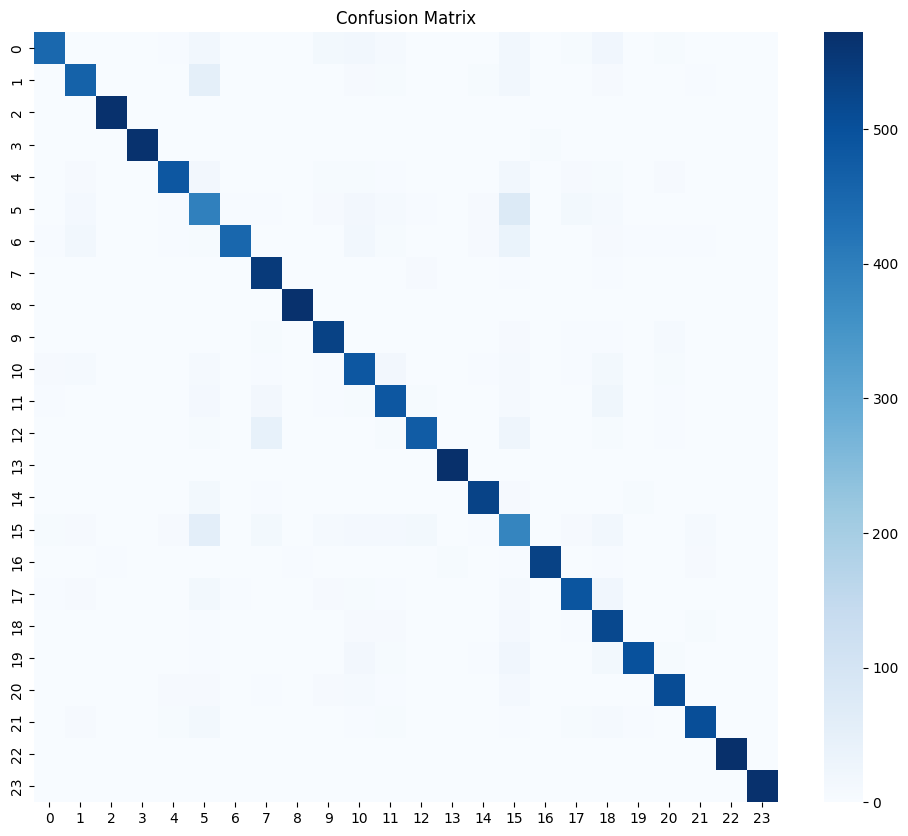

📈 Generating ROC curves...
215/215 ━━━━━━━━━━━━━━━━━━━━ 54s 249ms/step


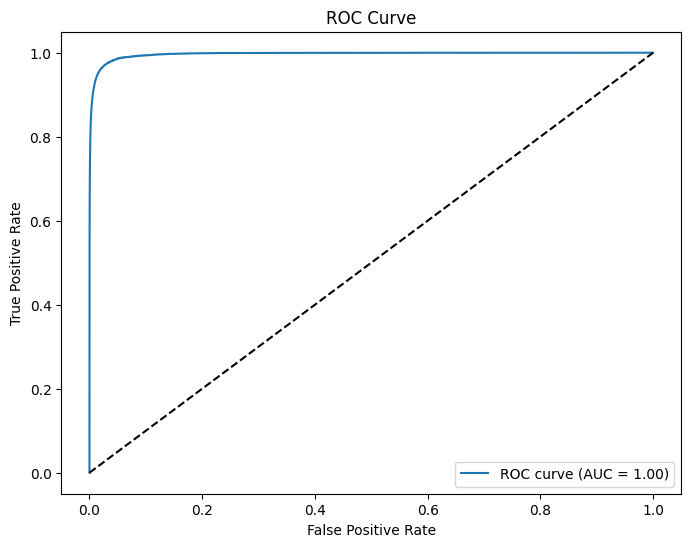

In [13]:
# ========================== #
# 6. EVALUATION
# ========================== #
print("🔍 Evaluating model...")
results = model.evaluate(test_data)
print(f"\n✅ Test Accuracy: {results[1]*100:.2f}%\n✅ Test Loss: {results[0]:.4f}")

# Confusion matrix
print("📊 Generating confusion matrix...")
y_true = test_data.classes
y_pred = np.argmax(model.predict(test_data), axis=1)

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(12, 10))
sns.heatmap(cm, annot=False, fmt="d", cmap="Blues")
plt.title("Confusion Matrix")
plt.show()

# ROC Curve
print("📈 Generating ROC curves...")
y_bin_true = label_binarize(y_true, classes=list(range(num_classes)))
y_bin_pred = model.predict(test_data)

fpr, tpr, _ = roc_curve(y_bin_true.ravel(), y_bin_pred.ravel())
roc_auc = auc(fpr, tpr)
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f"ROC curve (AUC = {roc_auc:.2f})")
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend(loc="lower right")
plt.show()


In [16]:
# ========================== #
# ADDITIONAL METRICS
# ========================== #
from sklearn.metrics import classification_report, accuracy_score, f1_score, precision_score, recall_score, balanced_accuracy_score

print("📌 Calculating additional metrics...")

y_true = test_data.classes
y_pred = np.argmax(model.predict(test_data), axis=1)

# Overall metrics
acc = accuracy_score(y_true, y_pred)
balanced_acc = balanced_accuracy_score(y_true, y_pred)
f1_w = f1_score(y_true, y_pred, average='weighted')
precision_w = precision_score(y_true, y_pred, average='weighted')
recall_w = recall_score(y_true, y_pred, average='weighted')

print(f"\n✅ Accuracy: {acc*100:.2f}%")
print(f"✅ Balanced Accuracy: {balanced_acc*100:.2f}%")
print(f"✅ Weighted F1 Score: {f1_w:.4f}")
print(f"✅ Weighted Precision: {precision_w:.4f}")
print(f"✅ Weighted Recall: {recall_w:.4f}")

# Detailed per-class classification report
print("\n📋 Classification Report:\n")
print(classification_report(y_true, y_pred, digits=4))


📌 Calculating additional metrics...
215/215 ━━━━━━━━━━━━━━━━━━━━ 50s 230ms/step

✅ Accuracy: 88.55%
✅ Balanced Accuracy: 88.55%
✅ Weighted F1 Score: 0.8875
✅ Weighted Precision: 0.8932
✅ Weighted Recall: 0.8855

📋 Classification Report:

              precision    recall  f1-score   support

           0     0.9201    0.7850    0.8472       572
           1     0.8585    0.8059    0.8314       572
           2     0.9947    0.9930    0.9939       572
           3     0.9982    0.9913    0.9947       572
           4     0.9186    0.8479    0.8818       572
           5     0.6226    0.6923    0.6556       572
           6     0.9698    0.7867    0.8687       572
           7     0.8392    0.9580    0.8947       572
           8     0.9913    0.9948    0.9930       572
           9     0.8869    0.9318    0.9088       572
          10     0.7810    0.8479    0.8131       572
          11     0.8234    0.8479    0.8355       572
          12     0.9368    0.8287    0.8794       572
     